# 🧪 Bayesian modelling for bioprocesses: hands-on

*AI Fundamentals for Biotechnology · Delft · 27 November 2026 · Dr Laura Marie Helleckes*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lhelleckes/bayesian-modelling-delft/blob/main/bayesian_modelling_bioprocesses.ipynb)

This notebook accompanies the slides. It has three parts:

| Part | Slides | What we do |
|---|---|---|
| **1. Fully mechanistic model** | 4, 13–14 | Fit first-order kinetics $P(t) = S_0 \cdot (1-e^{-k t})$ to four enzymes with PyMC |
| **2. Calibration models** | 16–20 | Build a likelihood for the absorbance measurement with `calibr8` and combine it with a linear process model |
| **3. Hybrid model** | 24–27 | Let the rate constant $k$ depend on temperature and pH through a Gaussian process |

All data are simulated, so we know the ground truth.

In [ ]:
# PyMC is pre-installed on Colab; calibr8 is not
!pip install --quiet pymc calibr8

In [2]:
import sys

import arviz as az
import calibr8
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor

if sys.platform == "darwin":
    # Optional: avoids clang errors on Apple Silicon Macs (not needed on Colab)
    pytensor.config.cxx = "/usr/bin/clang++"

ENZYME_STYLE = {
    "A": dict(color="dimgray", marker="x"),
    "B": dict(color="tab:blue", marker="o"),
    "C": dict(color="tab:red", marker="s"),
    "D": dict(color="tab:olive", marker="^"),
}

# Part 0: Simulate data for the demo

In [ ]:
rng = np.random.default_rng(2026)

# Measurement system: absorbance measurements saturates at high product concentration.
# Parameters for the true logistic model: L_L, L_U, log_I_x, S, c | scale_0, scale_1 | df
THETA_ABSORBANCE = [0.03, 5.0, 0.92, 4.2, 0.3, 0.01, 0.02, 5]


def measure_absorbance(concentration):
    mu = calibr8.xlog_asymmetric_logistic(np.asarray(concentration), THETA_ABSORBANCE[:5])
    scale = THETA_ABSORBANCE[5] + THETA_ABSORBANCE[6] * mu
    return mu + scale * rng.standard_t(THETA_ABSORBANCE[7], size=np.shape(mu))


# Parts 1 + 2: four enzymes, product formation in g/L (substrate is in excess)
P0_TRUE = 0.3
RATE_TRUE = {"A": 1.8, "B": 3.9, "C": 4.5, "D": 6.6}  # g/L/h
T_END = {"A": 2.0, "B": 2.0, "C": 1.9, "D": 1.5}  # h
rows = []
for enzyme, rate in RATE_TRUE.items():
    time = np.sort(np.concatenate([[rng.uniform(0.02, 0.05)], rng.uniform(0.07, T_END[enzyme], 9)]))
    product = P0_TRUE + rate * time
    for t, a in zip(time, measure_absorbance(product)):
        rows.append(dict(enzyme=enzyme, time=round(t, 3), absorbance=round(a, 3)))
kinetics = pd.DataFrame(rows)

# Part 2: calibration standards with known product concentration
standards = np.round(np.concatenate([np.geomspace(0.05, 2, 12), np.linspace(2.5, 17.5, 13)]), 2)
calibration = pd.DataFrame(dict(concentration=standards, absorbance=np.round(measure_absorbance(standards), 3)))


# Part 3: one enzyme screened at 100 conditions; the rate constant depends on T and pH
def simulate_kinetic_data(n_samples=100):
    T = rng.uniform(20, 50, n_samples)  # temperature in Celsius
    pH = rng.uniform(5, 9, n_samples)  # pH range

    # Latent model for log(k): decreasing with T, bell-shaped in pH with optimum at pH 7
    log_k_true = -0.03 * (T - 30) - 0.5 * (pH - 7) ** 2
    k = np.exp(log_k_true)

    time_points = np.linspace(0, 10, 20)
    data = []
    for i in range(n_samples):
        for t in time_points:
            S0 = 5.0
            P = S0 * (1 - np.exp(-k[i] * t))
            noise = rng.normal(0, 0.02)
            data.append({"SampleID": i, "Time": t, "P_obs": np.clip(P + noise, 0, None), "T": T[i], "pH": pH[i]})
    return pd.DataFrame(data)


kinetic_data = simulate_kinetic_data()
print("✅ Data ready: kinetics (Parts 1+2), calibration (Part 2), kinetic_data (Part 3)")

✅ Data ready: kinetics (Parts 1+2), calibration (Part 2), kinetic_data (Part 3)


---
## Part 1: Fully mechanistic model 🧪

We determine the reaction rate of **four enzymes**. The product is measured by **absorbance**.

A common approach is to estimate *initial rates* by linear regression on the first few points. But how many points should we choose? Instead, we fit a mechanistic model to **all** data points: an irreversible first-order reaction, where the reaction slows down because the substrate is used up:

$$P(t) = S_0 \cdot (1-e^{-k t})$$

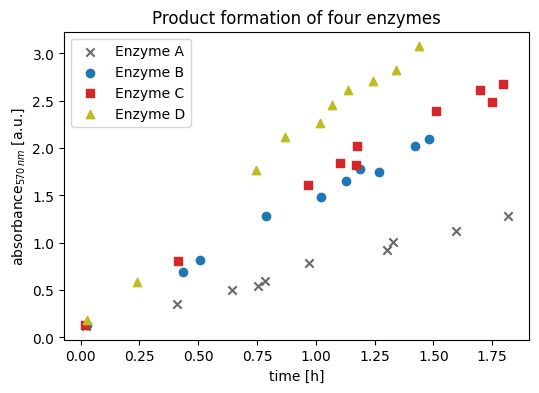

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
for enzyme, df in kinetics.groupby("enzyme"):
    ax.scatter(df["time"], df["absorbance"], label=f"Enzyme {enzyme}", **ENZYME_STYLE[enzyme])
ax.set(xlabel="time [h]", ylabel="absorbance$_{570\\,nm}$ [a.u.]", title="Product formation of four enzymes")
ax.legend()
plt.show()

The Bayesian model from the slides, with the absorbance used directly as the product signal:

- likelihood: $\mathcal{L}(Y_\mathrm{obs} \mid \hat{Y}) \sim \mathcal{N}(\mu, \sigma^2)$
- process model: $\mu = S_0 \cdot (1 - e^{-k \cdot t})$, with one $k$ per enzyme
- priors for $\sigma$, $k$ and $S_0$, where $S_0$ is the same for all enzymes because every well gets the same substrate

In [5]:
enzyme_idx, enzymes = pd.factorize(kinetics["enzyme"])
t = kinetics["time"].values
A_obs = kinetics["absorbance"].values

with pm.Model(coords={"enzyme": enzymes}) as first_order_model:
    # Priors
    sigma = pm.HalfNormal("sigma", sigma=1)
    k = pm.LogNormal("k", mu=np.log(0.5), sigma=1, dims="enzyme")  # [1/h]
    S0 = pm.Normal("S0", mu=5, sigma=0.5)

    # Mechanistic model
    P = S0 * (1 - pm.math.exp(-k[enzyme_idx] * t))

    # Likelihood
    pm.Normal("likelihood", mu=P, sigma=sigma, observed=A_obs)

    # Inference
    idata_first_order = pm.sample(1000, tune=1000, chains=4, target_accept=0.9, random_seed=42)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [sigma, k, S0]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


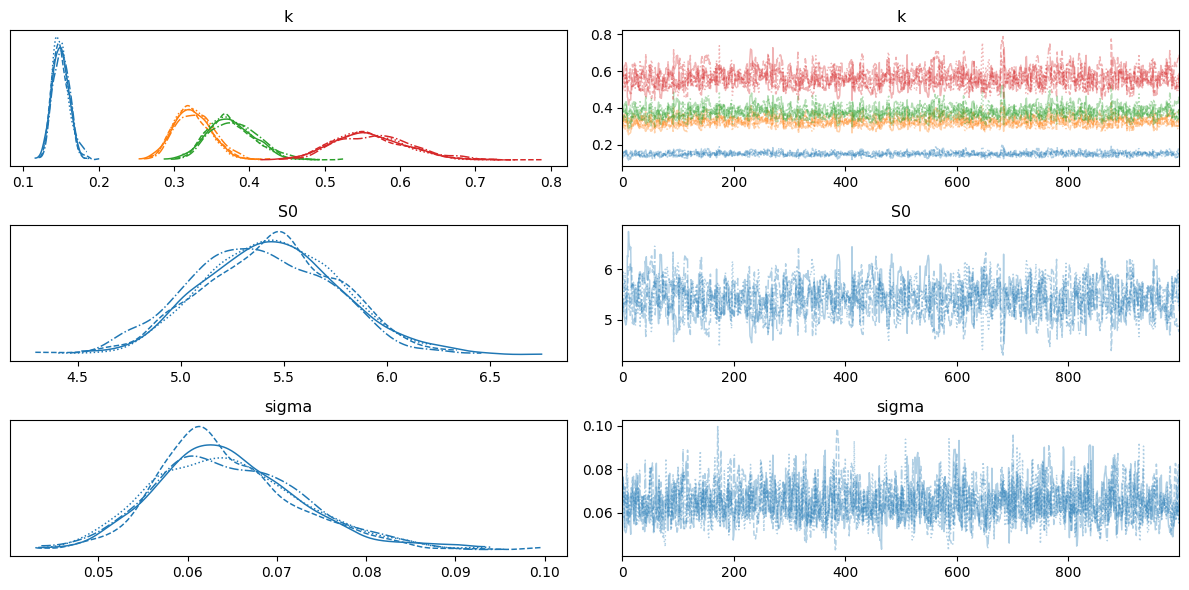

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k[A],0.150,0.011,0.130,0.170,0.000,0.000,638.0,1035.0,1.00
k[B],0.326,0.025,0.284,0.375,0.001,0.001,552.0,1048.0,1.00
k[C],0.377,0.032,0.322,0.435,0.001,0.001,542.0,1013.0,1.01
k[D],0.562,0.049,0.478,0.657,0.002,0.001,556.0,1052.0,1.01
S0,5.425,0.330,4.813,6.029,0.014,0.008,547.0,979.0,1.01
sigma,0.065,0.008,0.050,0.081,0.000,0.000,1473.0,1406.0,1.00


In [6]:
az.plot_trace(idata_first_order, var_names=["k", "S0", "sigma"])
plt.tight_layout()
plt.show()

az.summary(idata_first_order, var_names=["k", "S0", "sigma"])

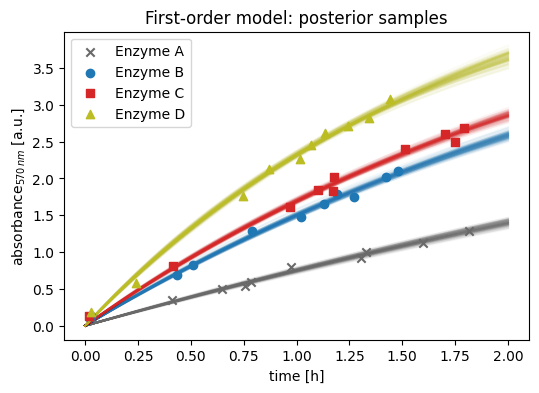

In [7]:
# Draw 100 posterior samples of the model curves
posterior = az.extract(idata_first_order, num_samples=100)
t_dense = np.linspace(0, 2, 100)

fig, ax = plt.subplots(figsize=(6, 4))
for e, enzyme in enumerate(enzymes):
    df = kinetics[kinetics["enzyme"] == enzyme]
    for i in range(100):
        k_i = posterior["k"].values[e, i]
        S0_i = posterior["S0"].values[i]
        ax.plot(t_dense, S0_i * (1 - np.exp(-k_i * t_dense)), color=ENZYME_STYLE[enzyme]["color"], alpha=0.05)
    ax.scatter(df["time"], df["absorbance"], label=f"Enzyme {enzyme}", zorder=3, **ENZYME_STYLE[enzyme])
ax.set(xlabel="time [h]", ylabel="absorbance$_{570\\,nm}$ [a.u.]", title="First-order model: posterior samples")
ax.legend()
plt.show()

The curves fit the data, and the model tells us that the reactions slow down because the substrate runs out.

**But:** does the non-linearity really come from the enzyme reaction, or from the measurement? ➡️ Part 2

> ✍️ **Try it yourself:** change the prior for `k` to something less informative, e.g. `pm.Uniform("k", lower=0.01, upper=5, dims="enzyme")`. How does that affect the posterior?

---
## Part 2: Calibration models 📏

To find out how absorbance relates to product concentration, we measure the absorbance for **known concentrations** of the product.

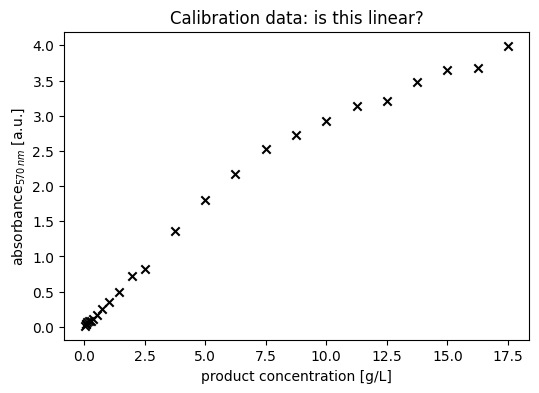

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(calibration["concentration"], calibration["absorbance"], color="black", marker="x")
ax.set(xlabel="product concentration [g/L]", ylabel="absorbance$_{570\\,nm}$ [a.u.]", title="Analytical calibration: measured standards")
plt.show()

With [`calibr8`](https://github.com/JuBiotech/calibr8) we build a calibration model that describes the **distribution of measurement outcomes** given the true concentration:

- trend: $\mu$ = `calibr8.xlog_asymmetric_logistic(x)` for the non-linear trend and the saturation of the measurement system
- noise: $\sigma$ = `calibr8.polynomial(μ)`, because the noise grows with the signal (heteroscedasticity)
- a Student-t distribution, which is robust to outliers

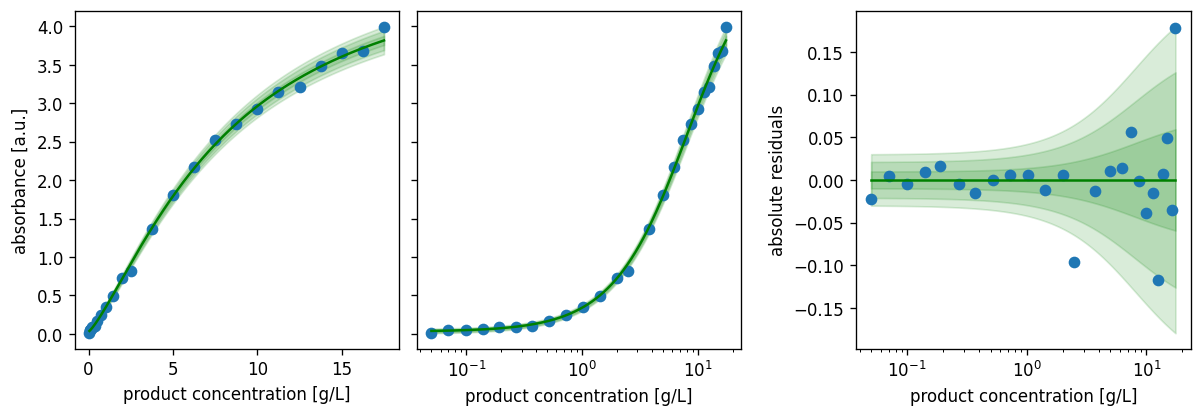

In [9]:
class ProductAbsorbanceModel(calibr8.BaseLogIndependentAsymmetricLogisticT):
    def __init__(self):
        super().__init__(independent_key="product concentration [g/L]", dependent_key="absorbance [a.u.]", scale_degree=1)


cm = ProductAbsorbanceModel()
theta_fit, history = calibr8.fit_scipy(
    cm,
    independent=calibration["concentration"].values,
    dependent=calibration["absorbance"].values,
    #             L_L    L_U    log_I_x  S       c        scale_0      scale_1   df
    theta_guess=[0, 5, 1, 4, 0, 0.02, 0.02, 5],
    theta_bounds=[(-0.5, 0.5), (3, 10), (0, 2), (0.5, 10), (-3, 3), (1e-3, 0.5), (0, 0.5), (1, 30)],
)
calibr8.plot_model(cm)
plt.show()

Now we go back to the enzyme kinetics. We use

- a **linear process model** for the product concentration: $P(t) = P_0 + v \cdot t$, with one rate $v$ per enzyme
- the **calibration model as the likelihood**: `cm.loglikelihood(...)` tells PyMC how likely the measured absorbance is for a given concentration

In [10]:
with pm.Model(coords={"enzyme": enzymes}) as linear_model:
    # Priors
    P0 = pm.HalfNormal("P0", sigma=1)  # product at t=0 [g/L]
    v = pm.HalfNormal("v", sigma=10, dims="enzyme")  # reaction rate [g/L/h]

    # Linear process model
    P = pm.Deterministic("P", P0 + v[enzyme_idx] * t)

    # Likelihood from the calibration model: absorbance given concentration
    cm.loglikelihood(x=P, y=A_obs, name="likelihood")

    # Inference
    idata_linear = pm.sample(1000, tune=1000, chains=4, target_accept=0.9, random_seed=42)

az.summary(idata_linear, var_names=["P0", "v"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [P0, v]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
P0,0.305,0.016,0.275,0.336,0.000,0.000,2937.0,2917.0,1.0
v[A],1.737,0.025,1.693,1.785,0.000,0.000,3158.0,2905.0,1.0
v[B],3.813,0.042,3.734,3.893,0.001,0.001,3579.0,3115.0,1.0
v[C],4.532,0.057,4.426,4.639,0.001,0.001,4087.0,2571.0,1.0
v[D],6.682,0.076,6.547,6.829,0.001,0.003,3734.0,1614.0,1.0


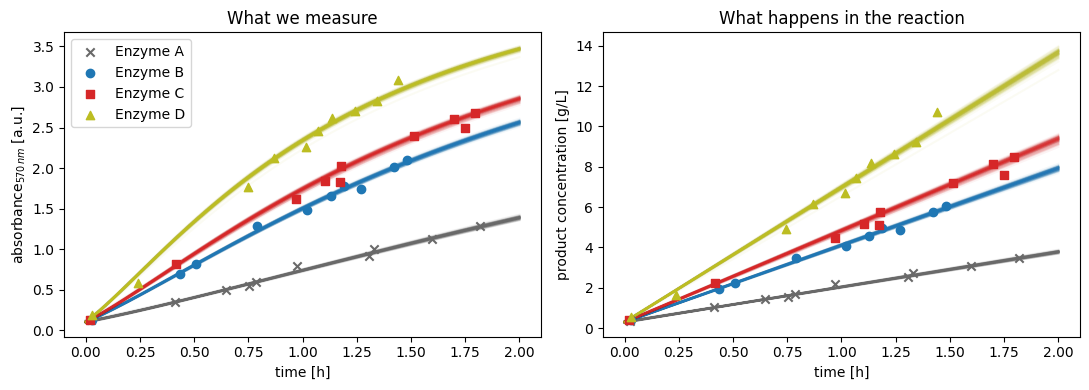

True rates [g/L/h]: {'A': 1.8, 'B': 3.9, 'C': 4.5, 'D': 6.6}


In [11]:
posterior = az.extract(idata_linear, num_samples=100)
t_dense = np.linspace(0, 2, 100)

fig, (ax_abs, ax_conc) = plt.subplots(1, 2, figsize=(11, 4))
for e, enzyme in enumerate(enzymes):
    df = kinetics[kinetics["enzyme"] == enzyme]
    style = ENZYME_STYLE[enzyme]
    for i in range(100):
        conc_i = posterior["P0"].values[i] + posterior["v"].values[e, i] * t_dense
        ax_abs.plot(t_dense, cm.predict_dependent(conc_i)[0], color=style["color"], alpha=0.05)
        ax_conc.plot(t_dense, conc_i, color=style["color"], alpha=0.05)
    ax_abs.scatter(df["time"], df["absorbance"], label=f"Enzyme {enzyme}", zorder=3, **style)
    # Measured absorbance converted to concentration with the inverse calibration model
    ax_conc.scatter(df["time"], cm.predict_independent(df["absorbance"].values), zorder=3, **style)

ax_abs.set(xlabel="time [h]", ylabel="absorbance$_{570\\,nm}$ [a.u.]", title="What we measure")
ax_conc.set(xlabel="time [h]", ylabel="product concentration [g/L]", title="What happens in the reaction")
ax_abs.legend()
plt.tight_layout()
plt.show()

print("True rates [g/L/h]:", RATE_TRUE)

The linear process model fits the data just as well. Taking the measurement into account changes the conclusion about the process:
**the substrate does not run out. The curvature comes from the saturating photometer.**

> ✍️ **Try it yourself:** we used the calibration parameters as fixed point estimates. `cm.loglikelihood(..., theta=...)` also accepts PyMC variables, so the calibration and the process model can be fitted together.

---
## Part 3: Hybrid model with a Gaussian process 🧠

In a screening, one enzyme was run under **100 different conditions** of temperature (T) and pH. The product concentration was measured directly, so we use a Normal likelihood again.

The rate constant `k` depends on the conditions, $k = f(T, \mathrm{pH})$, but we don't know the form of $f$. Instead of guessing a formula, we put a **Gaussian process prior** on $\log k$:

$$\mu = S_0 \cdot (1-e^{-k t}), \qquad \log k \sim \mathcal{GP}(m(x), \kappa(x, x'))$$

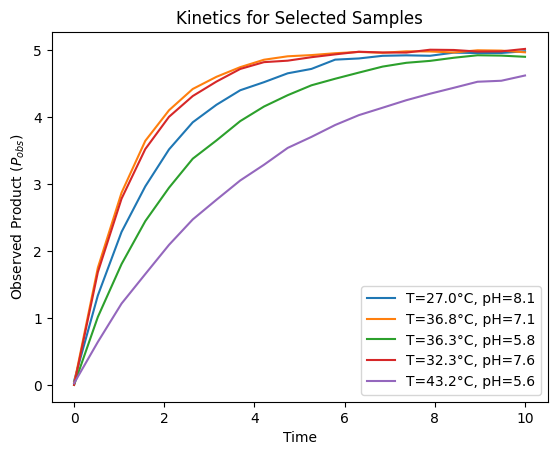

In [12]:
sample_ids_to_plot = [0, 10, 20, 30, 40]

for sid in sample_ids_to_plot:
    subset = kinetic_data[kinetic_data["SampleID"] == sid]
    label = f"T={subset['T'].iloc[0]:.1f}°C, pH={subset['pH'].iloc[0]:.1f}"
    plt.plot(subset["Time"], subset["P_obs"], label=label)

plt.xlabel("Time")
plt.ylabel("Observed Product ($P_{obs}$)")
plt.legend()
plt.title("Kinetics for Selected Samples")
plt.show()

PyMC needs a 2D matrix of observations (rows = samples, columns = time points). We also standardise `T` and `pH` (z-score), which makes the GP length scales easier to interpret.

In [13]:
unique_samples = kinetic_data[["SampleID", "T", "pH"]].drop_duplicates().reset_index(drop=True)
unique_times = np.sort(kinetic_data["Time"].unique())

# Reshape P_obs to matrix [samples x time]
P_obs_matrix = kinetic_data.pivot(index="SampleID", columns="Time", values="P_obs").values

# Standardise T and pH (used for the GP prior)
T_std = (unique_samples["T"] - unique_samples["T"].mean()) / unique_samples["T"].std()
pH_std = (unique_samples["pH"] - unique_samples["pH"].mean()) / unique_samples["pH"].std()
X = np.vstack([T_std, pH_std]).T
X.shape, P_obs_matrix.shape

((100, 2), (100, 20))

The latent GP over `log(k)` uses an `ExpQuad` kernel with separate length scales for T and pH.

In [14]:
coords = {
    "samples": unique_samples["SampleID"].values,
    "time": unique_times,
    "features": ["T", "pH"],
}

with pm.Model(coords=coords) as gp_model:
    # GP prior over log(k)
    ls = pm.HalfNormal("ls", sigma=1.0, dims="features")
    cov_func = pm.gp.cov.ExpQuad(input_dim=2, ls=ls)
    gp = pm.gp.Latent(mean_func=pm.gp.mean.Zero(), cov_func=cov_func)
    normalised_T_pH = pm.Data("normalised_T_pH", X, dims=("samples", "features"))
    # reparameterize=False (centred) samples better when the data are very informative
    log_k = gp.prior("log_k", X=normalised_T_pH, dims="samples", reparameterize=False)
    k = pm.Deterministic("k", pm.math.exp(log_k), dims="samples")

    # Mechanistic model
    tvals = pm.Data("time_values", unique_times, dims="time")
    # The initial substrate concentration is known, up to small pipetting errors
    S_0 = pm.Normal("S0", mu=5, sigma=0.1)
    P = pm.Deterministic("P", S_0 * (1 - pm.math.exp(-k[:, None] * tvals[None, :])), dims=("samples", "time"))

    # Likelihood
    sigma = pm.HalfNormal("sigma", sigma=1)
    pm.Normal("likelihood", mu=P, sigma=sigma, observed=P_obs_matrix, dims=("samples", "time"))

# Visualise the computation graph of the model
gp_model.to_graphviz()

In [ ]:
# Inference (⏱ takes 2–3 minutes on Colab)
with gp_model:
    idata_gp = pm.sample(500, tune=500, chains=1, target_accept=0.9, random_seed=42)

az.summary(idata_gp, var_names=["ls", "S0", "sigma"])

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [ls, log_k, S0, sigma]


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 84 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
ls[T],4.428,0.538,3.489,5.485,0.013,0.010,1851.0,1810.0,1.0
ls[pH],1.069,0.119,0.886,1.290,0.005,0.002,597.0,1540.0,1.0
S0,4.999,0.001,4.998,5.001,0.000,0.000,1360.0,1344.0,1.0
sigma,0.020,0.000,0.019,0.020,0.000,0.000,2716.0,1373.0,1.0


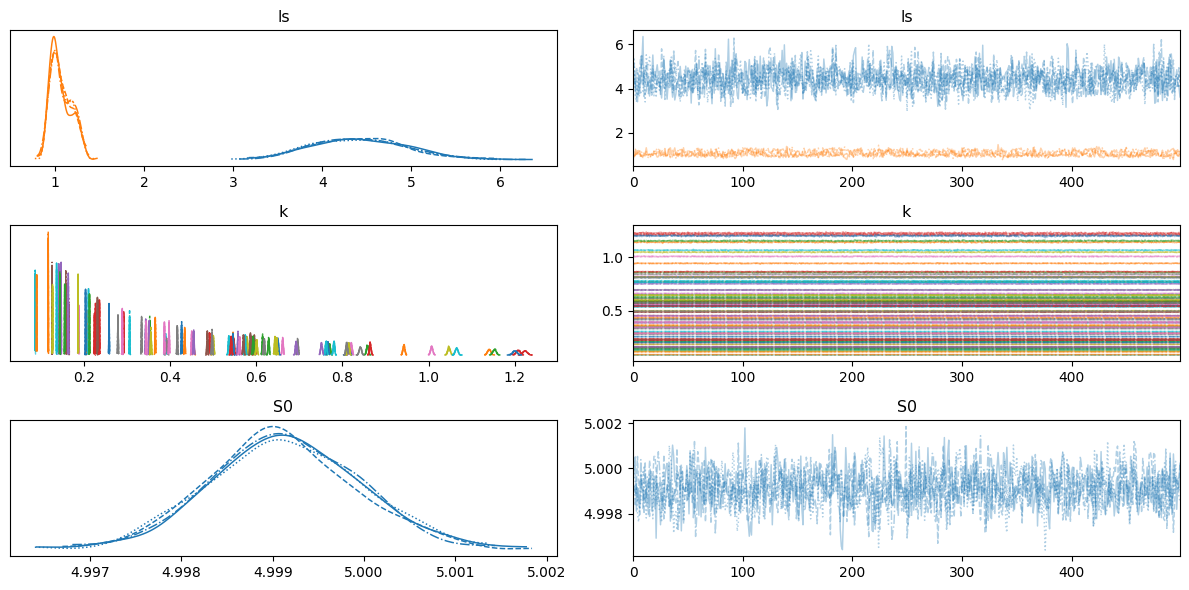

In [16]:
az.plot_trace(idata_gp, var_names=["ls", "k", "S0"])
plt.tight_layout()
plt.show()

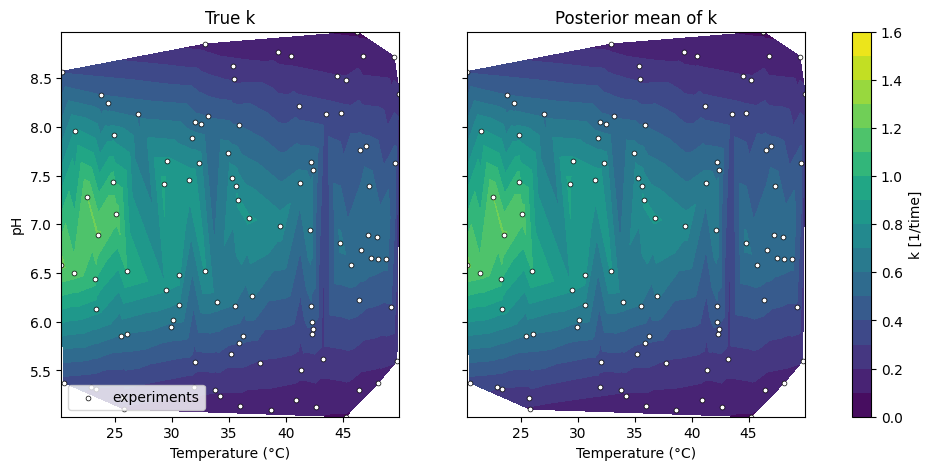

In [17]:
posterior = az.extract(idata_gp)
k_mean = posterior["k"].values.mean(axis=1)
k_true = np.exp(-0.03 * (unique_samples["T"] - 30) - 0.5 * (unique_samples["pH"] - 7) ** 2)

fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, values, title in zip(axs, [k_true, k_mean], ["True k", "Posterior mean of k"]):
    contour = ax.tricontourf(unique_samples["T"], unique_samples["pH"], values, levels=np.linspace(0, 1.6, 17), cmap="viridis")
    ax.scatter(unique_samples["T"], unique_samples["pH"], color="white", edgecolor="black", linewidth=0.5, s=12, label="experiments")
    ax.set(xlabel="Temperature (°C)", title=title)
axs[0].set_ylabel("pH")
axs[0].legend(loc="lower left")
fig.colorbar(contour, ax=axs, label="k [1/time]")
plt.show()

The GP recovers how `k` depends on temperature and pH without being told the functional form. Because the result is a posterior distribution, the uncertainty can be used for Bayesian optimisation and experimental design.

### 🧭 Bonus questions

1. Why might we prefer a latent GP prior over a fixed parametric form?
2. What do the length scales tell you about the sensitivity to T and pH?
3. Can you think of a way to incorporate replicate measurements?
4. Can you figure out the optimal conditions (T, pH)? How could you do that?